# Aprendizaje Reforzado
Es un tipo de Inteligencia Artificial (AI) donde un **agente** aprende qué decisiones tomar (**política**) dada una situación para maximizar la **recompensa** a largo plazo.




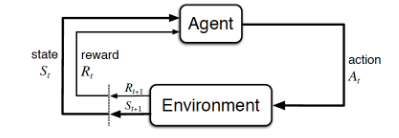




## Términos clave:
**POLÍTICA** ($\pi$): define el comportamiento del agente. Dado el estado del sistema, determina qué acción tomar.

**RECOMPENSA** ($R$): Como resultado de una acción podemos tener una recompensa (valor positivo) o una penalización (valor negativo).

**FUNCIÓN DE VALOR** ($V$): asociada a un estado, determina qué tan bueno es ese estado en el largo plazo. Es la recompensa total que un agente puede
esperar acumular  partiendo desde ese estado.

**MODELO DEL MUNDO**: permite predecir el próximo estado y recompensa, dado un estado actual y una acción tomada. No siempre se dispone de un modelo del mundo.

**OBJETIVO**: determinar una POLÍTICA óptima (maximize las recompensas recibidas en el largo plazo)


# COMPROMISO ENTRE EXPLORACIÓN Y EXPLOTACIÓN

**Exploración**: Tomar decisiones de las que se desconoce el resultado.

**Explotación**: Tomar decisiones cuyas consecuencias se han explorado.

**Acción greedy**: La accción que obtiene la máxima recompensa para un estado determinado.

## Caso de ejemplo: Máquinas tragamonedas

Supongamos que tenemos k máquinas tragamonedas donde la recompensa que devuelve cada una está dada por una distribución normal con varianza igual a 1 y una media propia de cada máquina.

Valores verdaderos de las acciones: [ 0.49671415 -0.1382643   0.64768854  1.52302986 -0.23415337]


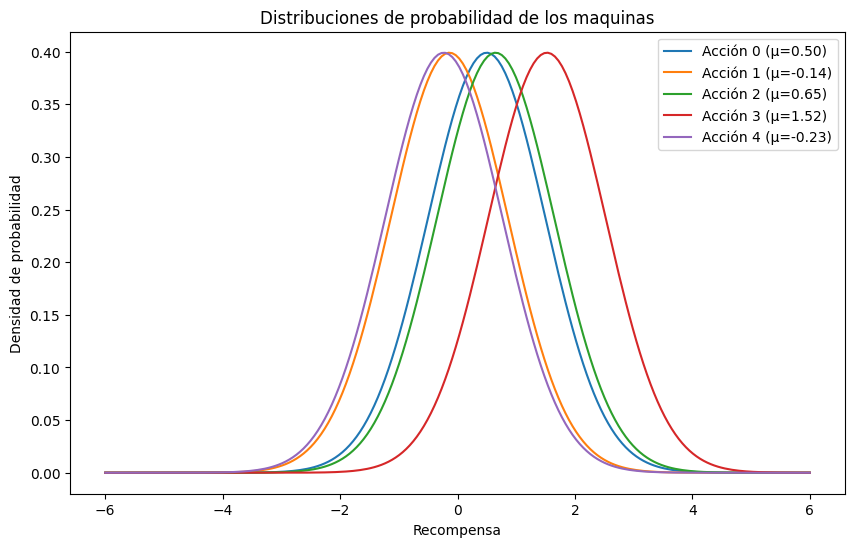

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# --- Configuración ---
np.random.seed(42)
k = 5  # Cantidad de máquinas
recompensa_media_maquina = np.random.normal(0, 1, k)   # tomamos k medias de una distribucion normal
variance = 1.0                             # varianza de las recompensas

print (f"Valores verdaderos de las acciones: {recompensa_media_maquina}")

# --- Graficar distribuciones ---
x = np.linspace(-6, 6, 200)  # rango de valores posibles de recompensa

plt.figure(figsize=(10,6))
for i in range(k):
    y = norm.pdf(x, loc=recompensa_media_maquina[i], scale=np.sqrt(variance))
    plt.plot(x, y, label=f"Acción {i} (μ={recompensa_media_maquina[i]:.2f})")

plt.title("Distribuciones de probabilidad de los maquinas")
plt.xlabel("Recompensa")
plt.ylabel("Densidad de probabilidad")
plt.legend()
plt.show()

Así, por ejemplo, si juego muchas veces en la maquina 0 voy a terminar con una ganancía de 0.5 en promedio. Si juego suficintes veces a la máquina 1 voy a terminar con una perdida promedio de 0.14.

La idea es encontrar un algoritmo que termine encontrando la máquina que da mayor recompensa en la menor cantidad de pasos, maximizando el beneficio, teniendo en cuenta que las recompensas responden a una función aleatoria.

## Estimación de recompensa

Vamos a empezar definiendo el valor estimado de una acción _a_ en un paso _t_ $ Q_t(a)$:

$$
Q_t(a) = E[R_t \mid A_t = a] = 
\frac{\sum_{i=1}^{t-1} R_i \, \mathbf{1}\{A_i = a\}}
     {\sum_{i=1}^{t-1} \mathbf{1}\{A_i = a\}}
$$

O sea, la recompensa para la acción _a_ se puede estimar como el promedio de las recompensas obtenidas por esa acción.

## Acción greedy
### Teoría:
La acción **Greedy** es la acción cuyo promedio de recompensas es mayor hasta el momento _t_.

La acción greedy se puede escribir de formá matematica como:
$A_g = \arg\max_{a} Q_t(a)$, siendo esta la acción con la cual se obtiene el máximo Q hasta el momento.


### Simulación:
Vamos a hacer un ejemplo donde un agente tiene como politica elegir la acción greedy.

Para esto definimos una función donde tome como argunmento el numero de maquina elegido y me devuelva una recompensa según su distribución de probabilidad.


In [2]:
def maquina(action):
    return np.random.normal(recompensa_media_maquina[action], 1.0)


Definamos la función para la politica greedy, incializando en cero las recomenzas esperadas Q para cada máquina y el numero de intentos:

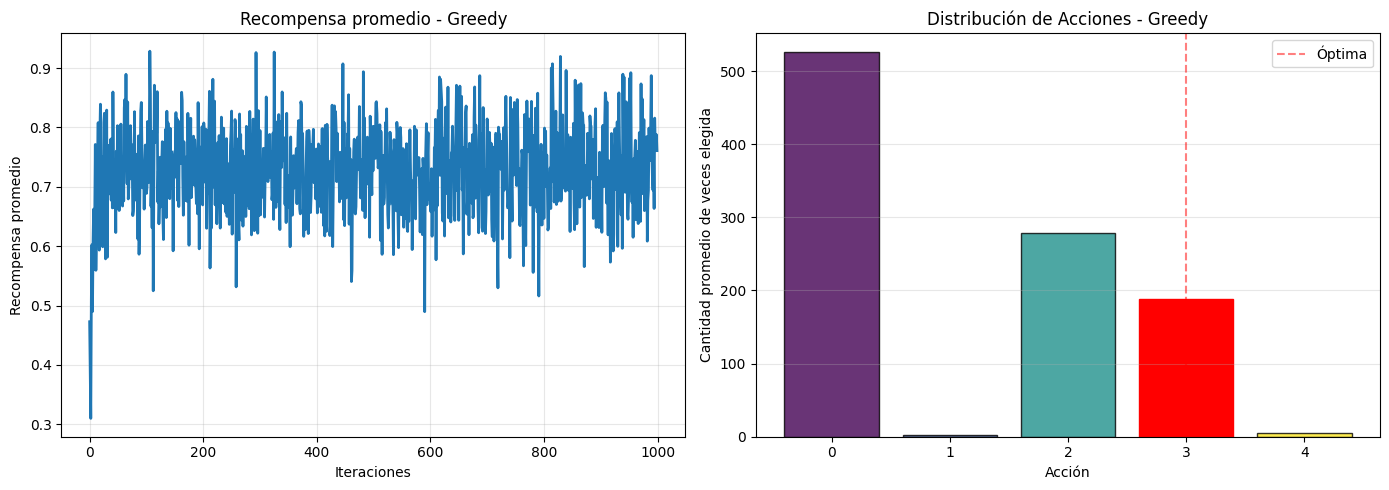

Acción más elegida: 0 (525.9 veces)
Porcentaje en acción óptima: 18.8%


In [3]:
steps = 1000 # Cantidad de pasos de la simulación
runs = 200   # Cantidad de simulaciones

# --- Política greedy ---
def run_greedy():
    Q = np.zeros(k) # Vector de recompensas esperadas
    N = np.zeros(k) # Vector de visitas
    rewards = []    # Vector de recompensas

    for t in range(1, steps+1): # Para cada iteración
        action = np.argmax(Q)   # Busco la acción que devuelva la mayor recompensa esperada
        r = maquina(action)     # Uso es máquina y guardo la recompensa
        N[action] += 1          # Le sumo una visita a la acción
        Q[action] += (r - Q[action]) / N[action] # Actualizo la recompenza esperada para la acción
        rewards.append(r)       # Guardo la recompenza para armar un historico
    return rewards, N

# --- Simulación ---
avg_rewards_greedy = np.zeros(steps)
total_actions_greedy = np.zeros(k)

for _ in range(runs):
    rewards_g, actions_g = run_greedy()
    avg_rewards_greedy += rewards_g
    total_actions_greedy += actions_g

avg_rewards_greedy /= runs
total_actions_greedy /= runs

optimal_action = np.argmax(recompensa_media_maquina)

# --- Gráficos ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recompensas promedio
axes[0].plot(avg_rewards_greedy, label="Greedy", linewidth=2)
axes[0].set_xlabel("Iteraciones")
axes[0].set_ylabel("Recompensa promedio")
axes[0].set_title("Recompensa promedio - Greedy")
axes[0].grid(alpha=0.3)

# Distribución de acciones
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = axes[1].bar(range(k), total_actions_greedy, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
axes[1].set_xlabel("Acción")
axes[1].set_ylabel("Cantidad promedio de veces elegida")
axes[1].set_title("Distribución de Acciones - Greedy")
axes[1].axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Estadísticas ---
most_chosen = np.argmax(total_actions_greedy)
print(f"Acción más elegida: {most_chosen} ({total_actions_greedy[most_chosen]:.1f} veces)")
print(f"Porcentaje en acción óptima: {100*total_actions_greedy[optimal_action]/steps:.1f}%")


### Algunas preguntas:

La acción más elegida no es la óptima. ¿Por qué?

¿Por qué las acciones 1 y 4 no se elijen?



## Política ε-greedy

### Teoría:
La política ε-greedy consiste en:

$A_t =
\begin{cases}
\arg\max_{a} Q_t(a), & \text{con probabilidad } 1-\varepsilon \\
\text{acción aleatoria}, & \text{con probabilidad } \varepsilon
\end{cases}$

En cada paso tengo una probabildad ($1-\varepsilon$) de usar la acción greedy (explotar) y una probabilidad $\varepsilon$ de usar una acción aleatoria (explorar).

Si los pasos en el ciclo tienden a infinito ($t \to \infty$) entonces la acción greedy tiende a la acción óptima (la de mayor recompensa), porque recorrí todas las acciónes suficientes veces como para encontrar la óptima.

### Simulación:


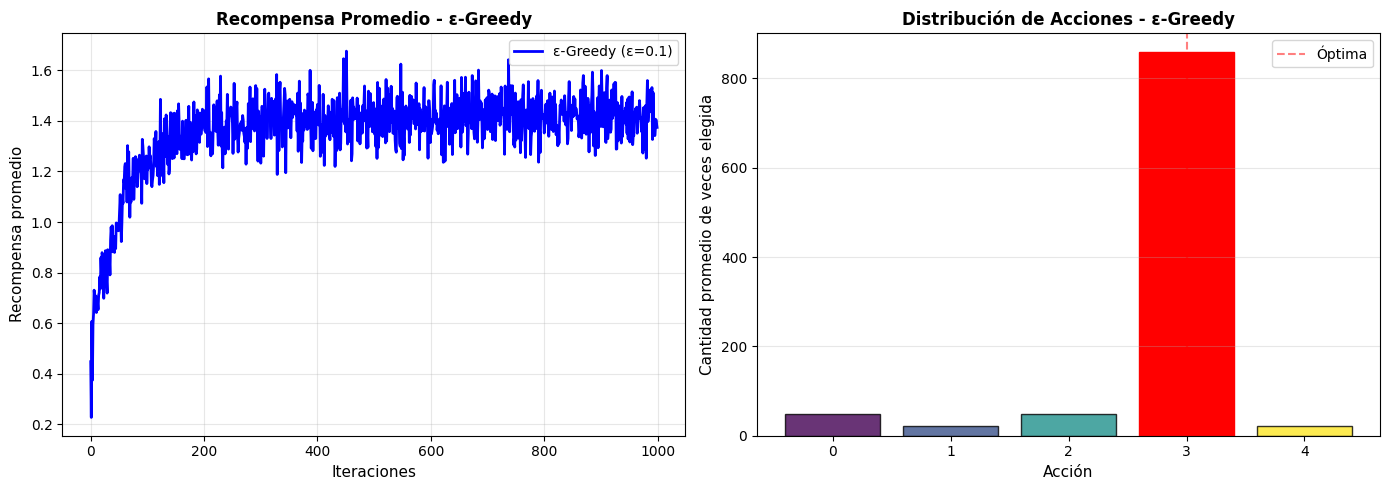

ε-GREEDY (ε=0.1):
  Acción más elegida: 3 (859.2 veces)
  Porcentaje en acción óptima: 85.9%


In [4]:
steps = 1000
runs = 200

def run_epsilon_greedy(epsilon=0.1):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    for t in range(1, steps+1):
        if np.random.rand() < epsilon:
            action = np.random.randint(k)
        else:
            action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, N

# --- Simulación ---
avg_rewards_eps = np.zeros(steps)
total_actions_eps = np.zeros(k)

for _ in range(runs):
    rewards_e, actions_e = run_epsilon_greedy(0.1)
    avg_rewards_eps += rewards_e
    total_actions_eps += actions_e

avg_rewards_eps /= runs
total_actions_eps /= runs

# --- Gráficos ---
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recompensas promedio
axes[0].plot(avg_rewards_eps, label="ε-Greedy (ε=0.1)", color='blue', linewidth=2)
axes[0].set_xlabel("Iteraciones", fontsize=11)
axes[0].set_ylabel("Recompensa promedio", fontsize=11)
axes[0].set_title("Recompensa Promedio - ε-Greedy", fontsize=12, fontweight='bold')
axes[0].grid(alpha=0.3)
axes[0].legend()

# Distribución de acciones
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = axes[1].bar(range(k), total_actions_eps, color=colors, alpha=0.8, edgecolor='black')
optimal_action = np.argmax(recompensa_media_maquina)
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
axes[1].set_xlabel("Acción", fontsize=11)
axes[1].set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
axes[1].set_title("Distribución de Acciones - ε-Greedy", fontsize=12, fontweight='bold')
axes[1].set_xticks(range(k))
axes[1].axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

# --- Resumen ---
most_chosen = np.argmax(total_actions_eps)
print(f"ε-GREEDY (ε=0.1):")
print(f"  Acción más elegida: {most_chosen} ({total_actions_eps[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_eps[optimal_action]/steps:.1f}%")


### Preguntas:
¿Qué hizo que en este caso se encuentre la acción de mayor recompensa?

¿Cuántas iteraciones fueron necesarias para lograrlo?


## Política UCB

### Teoría:
El método UCB (Upper-Confidence-Bound) selecciona la acción que maximiza no solo la recompensa promedio estimada, sino también un término de exploración que da más valor a las acciones menos probadas.

La acción elegida en un paso _t_ estará dada por:

$A_t = \arg\max_a \left[ \, Q_t(a) + c \, \sqrt{\frac{\ln t}{N_t(a)}} \, \right]$

Donde:
- $Q_t(a)$: valor estimado de la acción $a$ hasta el tiempo $t$  
- $N_t(a)$: número de veces que la acción $a$ fue seleccionada antes de $t$  
- $t$: número total de pasos hasta el momento  
- $c > 0$: parámetro que controla cuánta **exploración** queremos  

De la ecuación podemos observar lo siguiente:
- $Q_t(a)$ → premia acciones que parecen buenas  
- $\sqrt{\tfrac{\ln t}{N_t(a)}}$ → premia acciones poco probadas  
- El parámetro $c$ ajusta cuánto valoramos explorar  

### Simulación y comparación con métodos anteriores:

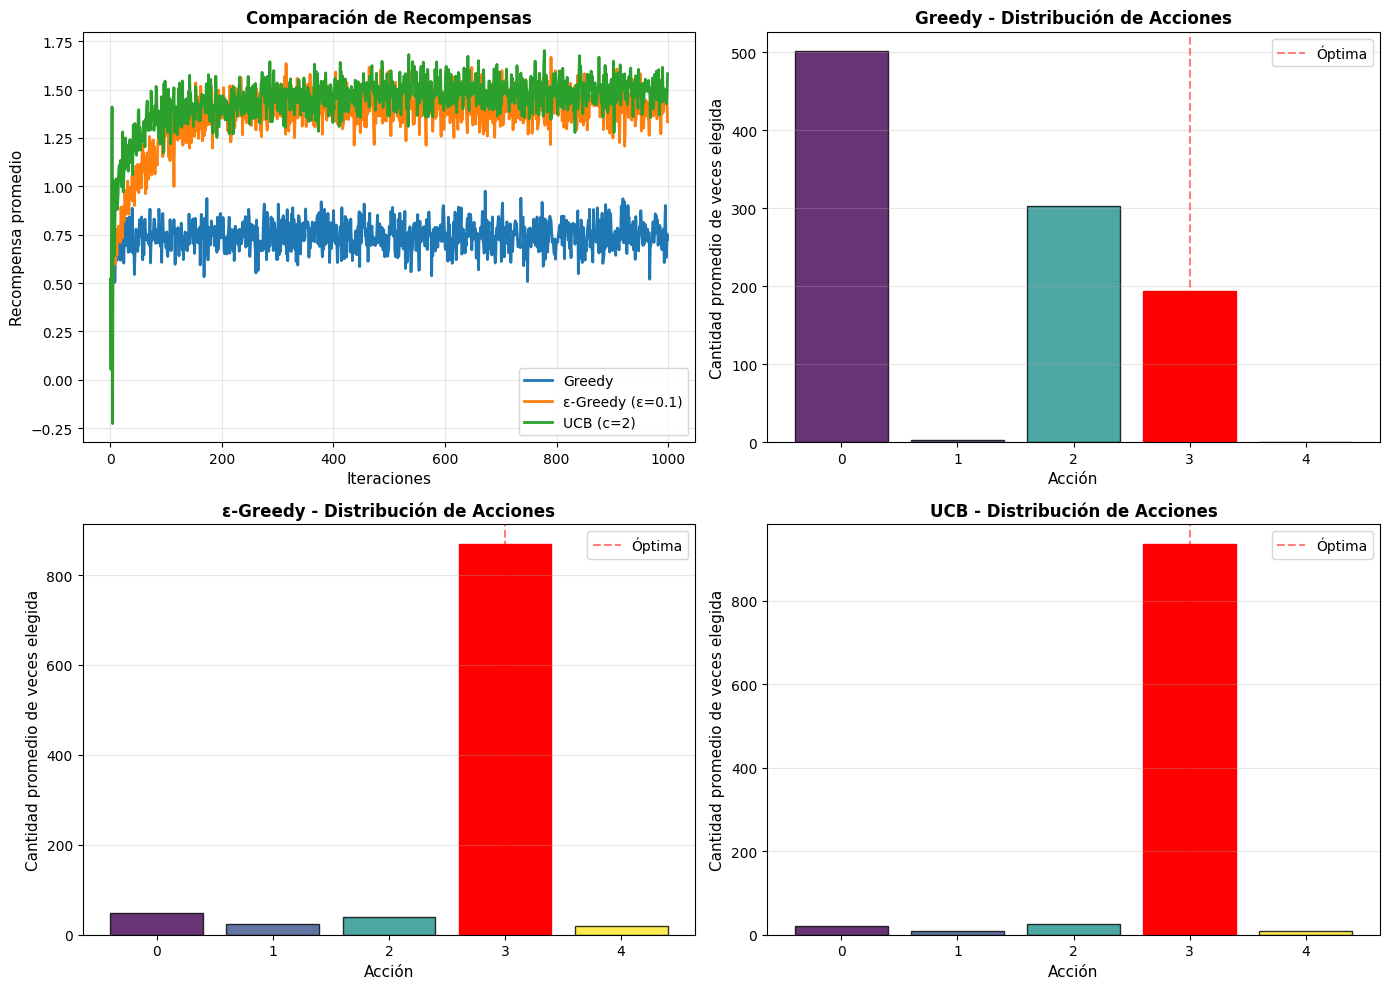


────────────────────────────────────────────────────────────

GREEDY:
  Acción más elegida: 0 (500.9 veces)
  Porcentaje en acción óptima: 19.3%

ε-GREEDY (ε=0.1):
  Acción más elegida: 3 (869.4 veces)
  Porcentaje en acción óptima: 86.9%

UCB (c=2):
  Acción más elegida: 3 (936.3 veces)
  Porcentaje en acción óptima: 93.6%


In [5]:
steps = 1000         # cantidad de iteraciones
runs = 200          # cantidad de simulaciones para promediar

def maquina(action):
    """Devuelve una recompensa al tomar la acción (ruido gaussiano agregado)."""
    return np.random.normal(recompensa_media_maquina[action], 1.0)

# --- Algoritmos (modificados para trackear acciones) ---
def run_greedy():
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)  # contador de acciones

    for t in range(1, steps+1):
        action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

def run_epsilon_greedy(epsilon=0.1):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)

    for t in range(1, steps+1):
        if np.random.rand() < epsilon:
            action = np.random.randint(k)
        else:
            action = np.argmax(Q)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

def run_ucb(c=2):
    Q = np.zeros(k)
    N = np.zeros(k)
    rewards = []
    action_counts = np.zeros(k)

    for t in range(1, steps+1):
        if 0 in N:
            action = np.argmin(N)
        else:
            ucb_values = Q + c * np.sqrt(np.log(t) / N)
            action = np.argmax(ucb_values)
        r = maquina(action)
        N[action] += 1
        action_counts[action] += 1
        Q[action] += (r - Q[action]) / N[action]
        rewards.append(r)
    return rewards, action_counts

# --- Simulación ---
avg_rewards_greedy = np.zeros(steps)
avg_rewards_eps = np.zeros(steps)
avg_rewards_ucb = np.zeros(steps)

# Acumuladores para las acciones
total_actions_greedy = np.zeros(k)
total_actions_eps = np.zeros(k)
total_actions_ucb = np.zeros(k)

for _ in range(runs):
    rewards_g, actions_g = run_greedy()
    rewards_e, actions_e = run_epsilon_greedy(0.1)
    rewards_u, actions_u = run_ucb(2)

    avg_rewards_greedy += rewards_g
    avg_rewards_eps += rewards_e
    avg_rewards_ucb += rewards_u

    total_actions_greedy += actions_g
    total_actions_eps += actions_e
    total_actions_ucb += actions_u

avg_rewards_greedy /= runs
avg_rewards_eps /= runs
avg_rewards_ucb /= runs

total_actions_greedy /= runs
total_actions_eps /= runs
total_actions_ucb /= runs

# --- Gráficos ---
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Gráfico de recompensas (como antes)
ax1 = axes[0, 0]
ax1.plot(avg_rewards_greedy, label="Greedy", linewidth=2)
ax1.plot(avg_rewards_eps, label="ε-Greedy (ε=0.1)", linewidth=2)
ax1.plot(avg_rewards_ucb, label="UCB (c=2)", linewidth=2)
ax1.set_xlabel("Iteraciones", fontsize=11)
ax1.set_ylabel("Recompensa promedio", fontsize=11)
ax1.set_title("Comparación de Recompensas", fontsize=12, fontweight='bold')
ax1.legend()
ax1.grid(alpha=0.3)

# 2. Distribución de acciones - Greedy
ax2 = axes[0, 1]
colors = plt.cm.viridis(np.linspace(0, 1, k))
bars = ax2.bar(range(k), total_actions_greedy, color=colors, alpha=0.8, edgecolor='black')
optimal_action = np.argmax(recompensa_media_maquina)
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax2.set_xlabel("Acción", fontsize=11)
ax2.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax2.set_title("Greedy - Distribución de Acciones", fontsize=12, fontweight='bold')
ax2.set_xticks(range(k))
ax2.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

# 3. Distribución de acciones - ε-Greedy
ax3 = axes[1, 0]
bars = ax3.bar(range(k), total_actions_eps, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax3.set_xlabel("Acción", fontsize=11)
ax3.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax3.set_title("ε-Greedy - Distribución de Acciones", fontsize=12, fontweight='bold')
ax3.set_xticks(range(k))
ax3.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax3.legend()
ax3.grid(axis='y', alpha=0.3)

# 4. Distribución de acciones - UCB
ax4 = axes[1, 1]
bars = ax4.bar(range(k), total_actions_ucb, color=colors, alpha=0.8, edgecolor='black')
bars[optimal_action].set_color('red')
bars[optimal_action].set_alpha(1.0)
ax4.set_xlabel("Acción", fontsize=11)
ax4.set_ylabel("Cantidad promedio de veces elegida", fontsize=11)
ax4.set_title("UCB - Distribución de Acciones", fontsize=12, fontweight='bold')
ax4.set_xticks(range(k))
ax4.axvline(optimal_action, color='red', linestyle='--', alpha=0.5, label='Óptima')
ax4.legend()
ax4.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()


print(f"\n{'─'*60}")
print("\nGREEDY:")
most_chosen = np.argmax(total_actions_greedy)
print(f"  Acción más elegida: {most_chosen} ({total_actions_greedy[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_greedy[optimal_action]/steps:.1f}%")

print(f"\nε-GREEDY (ε=0.1):")
most_chosen = np.argmax(total_actions_eps)
print(f"  Acción más elegida: {most_chosen} ({total_actions_eps[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_eps[optimal_action]/steps:.1f}%")

print(f"\nUCB (c=2):")
most_chosen = np.argmax(total_actions_ucb)
print(f"  Acción más elegida: {most_chosen} ({total_actions_ucb[most_chosen]:.1f} veces)")
print(f"  Porcentaje en acción óptima: {100*total_actions_ucb[optimal_action]/steps:.1f}%")
print("="*60)

### Preguntas
¿Por qué la recompensa media de UCB es mayor a la de ε-greedy?


# Procesos de Markov


En un proceso de Markov el estado actual del entorno (environment) caracteriza completamente la evolución del proceso (independientemente del pasado / camino recorrido).

En estos procesos el agente se encuentra en un estado ($S_t$) y al interactura con una acción ($A_t$) de todas las acciones posibles en ese estado ($A_t \in \mathcal{A}$), pasa al estado siguiente ($S_{t+1}$) y obtiene una recompensa ($R_{t+1}$), los cuales responden a un función de probabilidad. En un proceso de decisión de Markov $S_t$ y $R_t$ dependen exclisivamente del par estado y acción inmediatamente anterior, y no del resto de la historia del proceso.


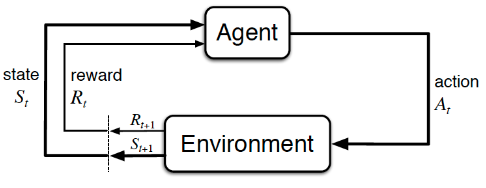


Las máquinas del ejemplo anterior eran Procesos  de  Decisión  de  Markov  con un único estado.

## Algunos conceptos necesarios:

* $S_t$: estado en el tiempo (t).
* $A_t$: acción tomada en el tiempo (t).
* $R_{t+1}$: recompensa observada al pasar de $(S_t)$ a $(S_{t+1})$.
* $\mathcal{S}$: espacio de estados.
* $\mathcal{A}(s)$: acciones disponibles en el estado (s).
- $P(s'|s,a)$:Probabilidad de transición: probabilidad de llegar a s' desde s tomando acción a.  
- $R(s,a,s')$: Recompensa esperada al ir de s a s' con acción a.  
- $G_t$: Retorno: suma descontada de recompensas futuras, $G_t = \sum_{k=0}^{\infty} \gamma^k R_{t+k+1} = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \cdots$.  
- $γ$ - Factor de descuento, cuánto importa el futuro $(0 \le \gamma \le 1)$.  
- $v_π(s) = E[G_t|S_t=s]$ : Valor de estado: recompensa esperada siguiendo política π desde s.  
- $π(a|s)$ : Política: probabilidad de elegir acción a en estado s.  
- $π_*(s) = argmax_a q_*(s,a)$: Política óptima greedy: elegir la acción con mayor valor óptimo.



La Ecuación de Bellman establece la relación entre el valor de un estado S y los valores de los posibles estados siguientes s'. La Ecuación de Bellman para una política $\pi$ estpa dada por:

$$
v_\pi(s) = \sum_a \pi(a|s) \sum_{s',r} p(s',r|s,a) \big[ r + \gamma v_\pi(s') \big]
$$

**Explicación de los términos:**

- $v_π(s)$ valor esperado del estado s siguiendo la política π.  
- $π(a|s)$ probabilidad de elegir la acción a en el estado s según la política π.  
- $P(s',r|s,a)$ probabilidad de que, al tomar acción a en s, el siguiente estado sea s' y se reciba recompensa r.  
- $r$ recompensa inmediata obtenida al pasar de s a s' con acción a.  
- $γ$ factor de descuento, pondera la importancia de las recompensas futuras.  
- $v_π(s)$ valor esperado del siguiente estado s', según la política π.  
- $Σ_a Σ_{s',r}$ promedia sobre todas las acciones posibles y todos los resultados posibles de la acción.


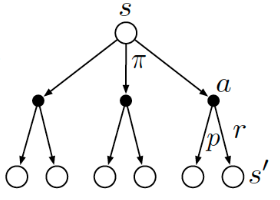

## a - Programación dinámica: Iteración de valores

Un procedimiento para encontrar la politica óptima es el denominado **algoritmo de iteración por valores**. Esto permite calcular numéricamente los valores de los estados y los valores de las acciones en los Procesos de Decisión de Markov (MDPs) con probabilidades de transición y recompensas conocidas. El procedimiento (para los valores de los estados) incluye los siguientes pasos:

1.  **Inicializar** los valores de todos los estados, V(s), con algún valor inicial (generalmente cero).
2.  Para cada estado, *s*, en el MDP, **realizar la actualización de Bellman**:
    
$$
v_{k+1} = \max_a \sum_{s',r} p(s',r|s,a) \big[ r + \gamma v_k(s') \big]
$$

3.  **Repetir** el paso 2 durante un número grande de iteraciones o hasta que los cambios sean demasiado pequeños.

Este algoritmo converge a la solución óptima pero tiene la limitación de que hay que iterar por todos los estados y acciones posibles (computacionalmente costoso), y se tiene que conocer la probabilidad de transición para cada par acción/recompensa.

Veamos el siguiete ejemplo (Sutton & Barto, p84):

Un jugador tiene la oportunidad de apostar en los resultados de una serie de lanzamientos de moneda. Si la moneda sale cara, gana tantos dólares como haya apostado en ese lanzamiento; si sale cruz, pierde lo apostado. El juego termina cuando el jugador gana al alcanzar su objetivo de $100, o pierde al quedarse sin dinero. En cada lanzamiento, el jugador debe decidir qué porción de su capital apostar, en números enteros de dólares. ¿Cuál es la política que maximice las probabilidades de alcanzar el objetivo?

Apliquemos el método de iteración de valores en este ejemplo:

Iteración 1
Iteración 2
Iteración 3
Iteración 4
Iteración 5
Iteración 6
Iteración 7
Iteración 8
Iteración 9
Iteración 10
Iteración 11
Iteración 12


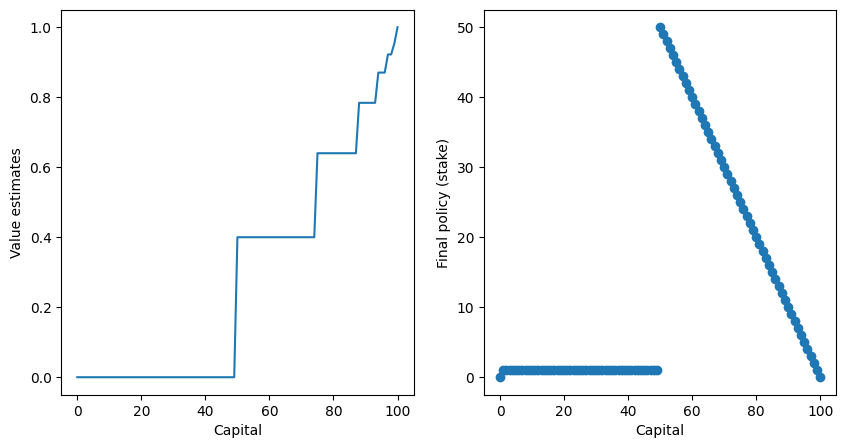

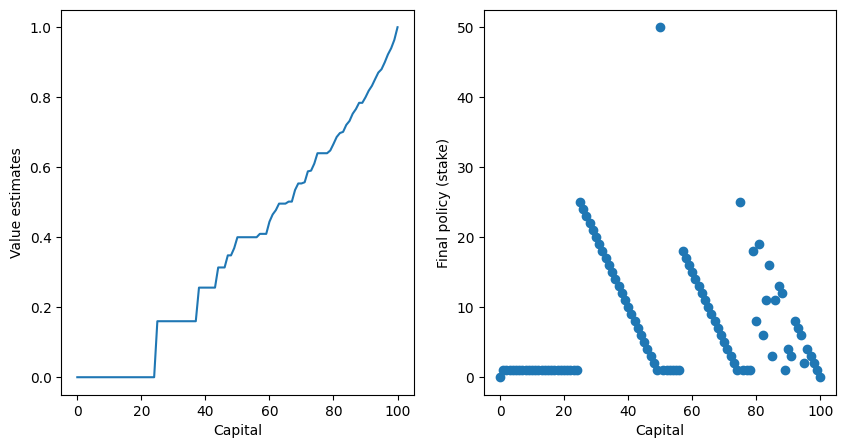

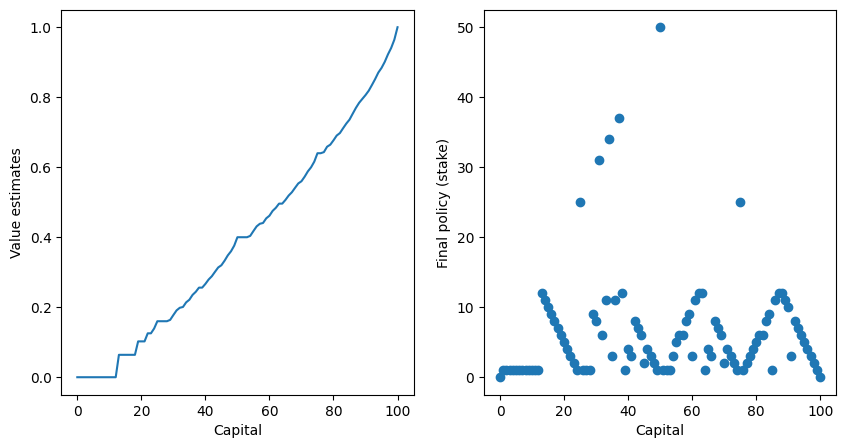

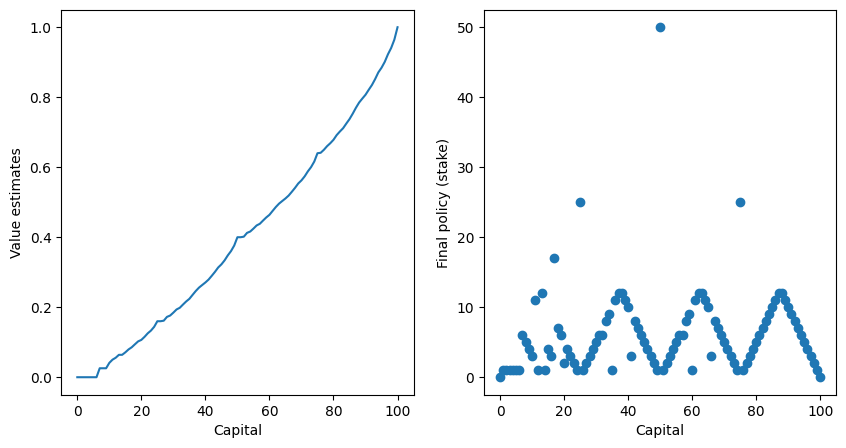

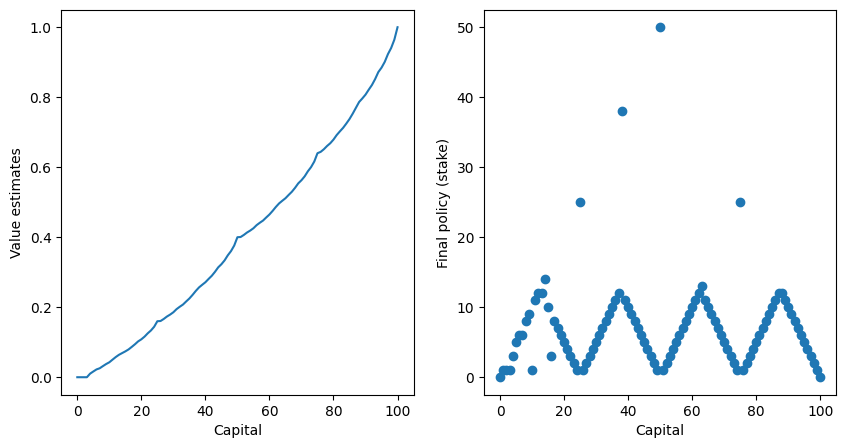

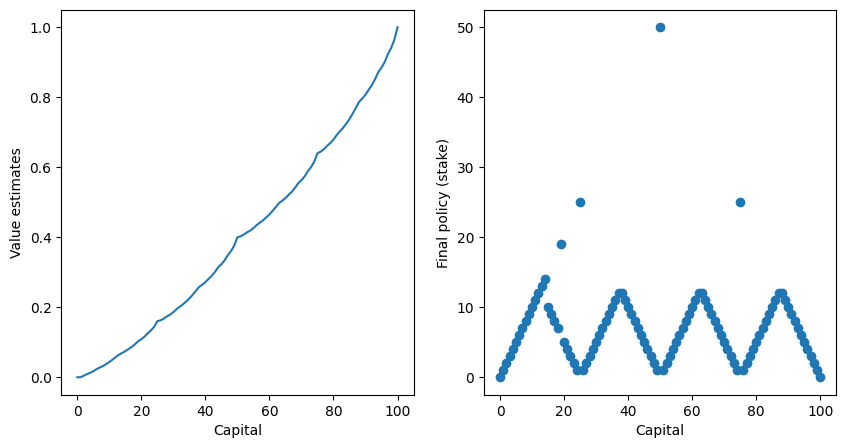

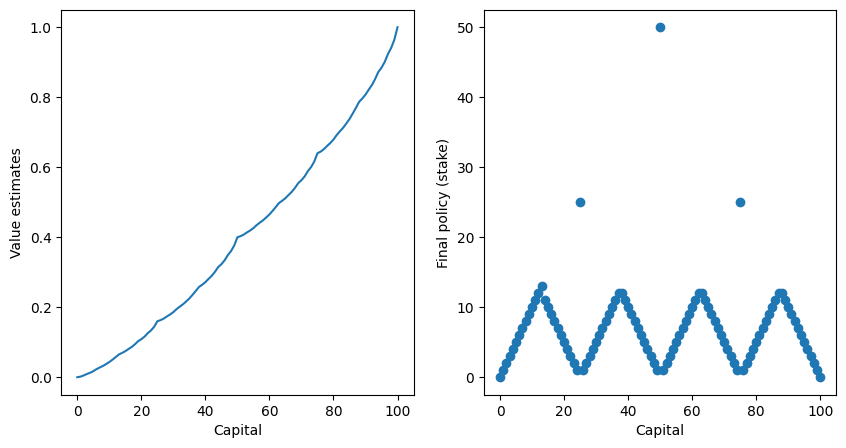

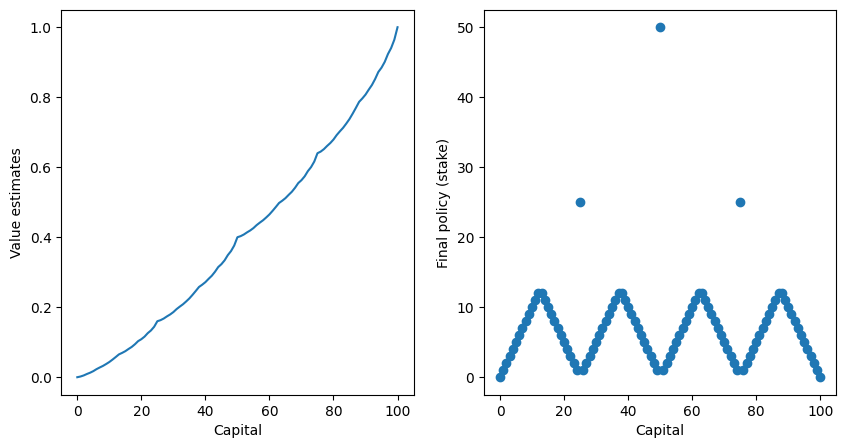

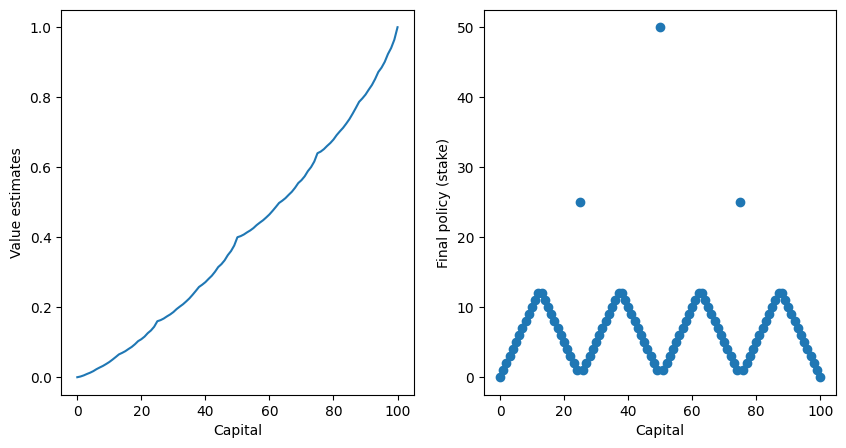

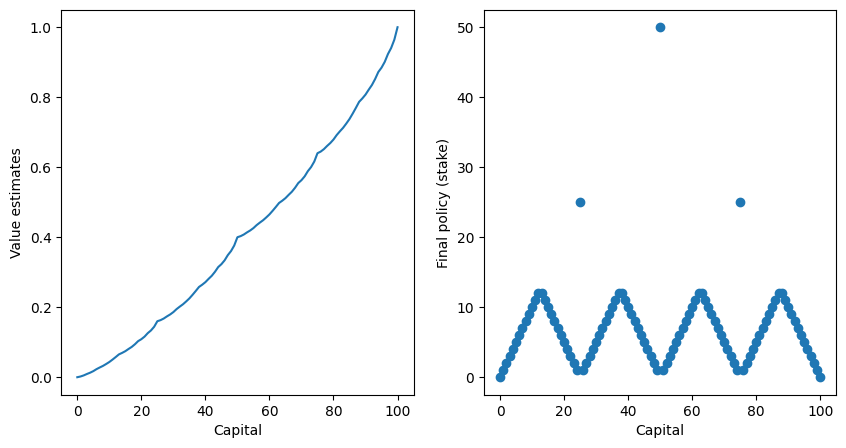

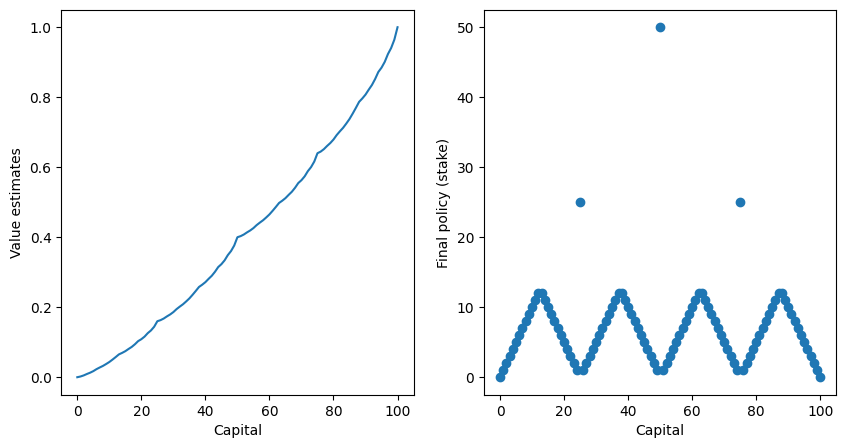

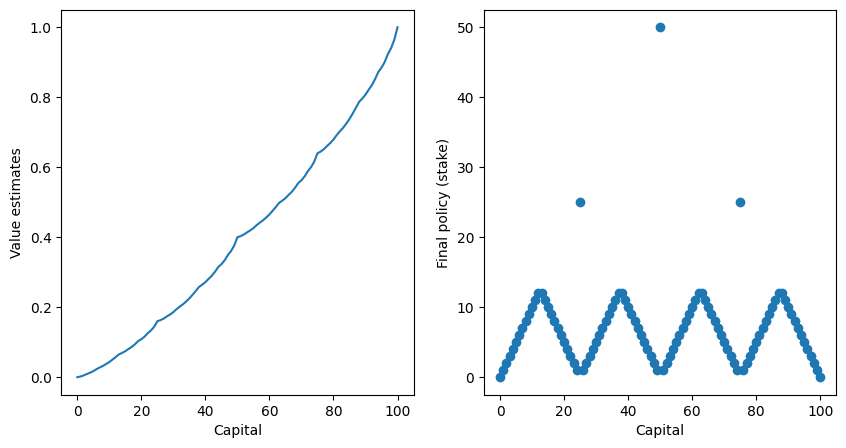

In [6]:
import numpy as np
import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt

GOAL = 100 # objetivo
STATES = np.arange(GOAL + 1) # todos los estados, incluyendo s 0 and s 100
HEAD_PROB = 0.4 # Probabilidad de sacar cara

# Estados
state_value = np.zeros(GOAL + 1) # Valor esperado en cada estado (prob de ganar)
state_value[GOAL] = 1.0

# Array donde voy a guardar la política (cantidad a apostar para cada estado)
policy = np.zeros(GOAL + 1)

iteration = 0

niter = 12
while True:
    iteration += 1
    print('Iteración %d' % (iteration))

    delta = 0.0 # Evaluo el cambio de los valores, para ver si ya convergió a una solución
    for state in STATES[1:GOAL]: # recorro todos los estados
        # Obtener todas la acciones para el estado actial
        actions = np.arange(min(state, GOAL - state) + 1) # puedo apostar de 1 hasta lo que tengo, o lo que me falta para ganar
        action_returns = []
        for action in actions:
            action_returns.append(
                HEAD_PROB * state_value[state + action] + (1 - HEAD_PROB) * state_value[state - action])
            # para cada acción guardo la recompensa esperada.
            # Esto es la prob de ganar por el estado si gano + la prob de perder por el estado si pierdo.
        new_value = np.max(action_returns) # Guardo la acción que retorna la maxima recompensa
        delta += np.abs(state_value[state] - new_value) # Calculo la diferencia con la iteración anterior
        state_value[state] = new_value # guardo el nuevo resultado
        policy[state] = actions[np.argmax(np.round(action_returns[1:], 5)) + 1] # +1 porque la función me devuelve el indice del array
        # guardo mi politica como la acción que maximiza la probabilidad de ganar para cada estado


    _, axes = plt.subplots(1, 2, figsize=(10, 5))
    plt.subplots_adjust(wspace=0.2, hspace=0.2)
    axes = axes.flatten()

    # Plot Values
    plt.subplot(1, 2, 1)
    plt.plot(state_value)
    plt.xlabel('Capital')
    plt.ylabel('Value estimates')

    # Plot Policy
    plt.subplot(1, 2, 2)
    plt.scatter(STATES, policy)
    plt.xlabel('Capital')
    plt.ylabel('Final policy (stake)')

    if iteration == niter or delta < 1e-9:
        break


### Preguntas:
¿Por qué la politica optimá tiende a esa forma?

Ejercicio. Que pasa si la posibilidad de sacar cara es 0.6. Explicar el resultado obtenido
a medida que las iteraciones avanzan voy sabiendo mejor las posibilidades de ganar del proximo estado, tanto como si gano como si pierdo
tambien porque el delta premia a las politcas que llegan al objetivo más rapidamete, la funcioón de valor es mayor

## Ejemplo Montecarlo

En el ejemplo anterior conocía el modelo del mundo, el cual tenía pocos estados y acciones. Podía calcular la función de valor de cada uno e iterara hasta encontrar la óptima.
Pero ¿qué hago cuando no tengo un modelo del mundo o los estados son demasiados como para iterar?

Los métodos de Monte Carlo permiten aprender la **función de valor de estado** de una política dada.
Recordemos que el **valor de un estado $v(s)$** es el **retorno esperado** —es decir, la **recompensa acumulada futura con descuento esperada**— al comenzar desde ese estado.
Una forma de estimarlo consiste en **promediar los retornos observados** después de las visitas a ese estado.
A medida que se observan más retornos, el promedio debería **converger al valor esperado**.
Esta idea es la base de todos los métodos de Monte Carlo.

En particular, supongamos que deseamos estimar $v_\pi(s)$, el valor de un estado $s$ bajo una política $\pi$, dado un conjunto de episodios obtenidos siguiendo dicha política y pasando por $s$.
Cada vez que el estado $s$ aparece en un episodio se denomina **una visita a $s$**.


Resumeniendo, en Montecarlo actualizo la función de valor con el promedio de valores observados en cada episodio. Si las visitas al estado $s$ tienden a infinito, la función de valor converge a $v_\pi$.

El valor de un estado $s$ bajo la política $\pi$ se estima como:

$$
v_\pi(s) = \mathbb{E}_\pi [ G_t \mid S_t = s ]
$$

donde:

- $S_t$ es el estado en el tiempo $t$  
- $G_t$ es el **retorno** desde el tiempo $t$ hasta el final del episodio:  
  $$
  G_t = R_{t+1} + \gamma R_{t+2} + \gamma^2 R_{t+3} + \dots = \sum_{k=0}^{T-t-1} \gamma^k R_{t+k+1}
  $$  
- $\gamma \in [0,1]$ es el **factor de descuento**  
- $\mathbb{E}_\pi[\cdot]$ denota el **promedio sobre todos los episodios** generados siguiendo la política $\pi$


#### Ejemplo politica predefinida - Encontrando función de valor - Black Jack

El objetivo del juego de casino **blackjack** es obtener cartas cuya suma sea lo más cercana posible a **21 sin pasarse**.
Las figuras valen **10**, y el **as** puede valer **1 o 11**. En esta versión, cada jugador compite solo contra el crupier.

El juego empieza con **dos cartas** para ambos. Una carta del crupier se muestra y la otra queda oculta.
Si el jugador tiene 21 desde el inicio (un as y una carta de valor 10), se llama **“natural”** y gana automáticamente, salvo que el crupier también tenga uno (empate).
Si no tiene un natural, el jugador puede **pedir cartas (“hit”)** o **plantarse (“stick”)**.
Si supera 21, **pierde**.
Luego juega el crupier, quien sigue una regla fija: **se planta con 17 o más**, y **pide** con menos.
Si el crupier se pasa, gana el jugador; si no, gana quien tenga la suma más cercana a 21.

Cada partida puede modelarse como un **proceso de decisión de Markov (MDP) finito**:

* Cada juego es un episodio.
* Las recompensas son: **+1 si gana**, **–1 si pierde**, **0 si empata**.
* No hay descuento ($\gamma = 1$).
* Las acciones posibles son *hit* o *stick*.
* El estado depende de tres factores:

  1. La **suma actual** del jugador (12–21),
  2. La **carta visible del crupier** (A–10),
  3. Si el jugador tiene o no un **as usable** (que puede contar como 11 sin pasarse).

Esto genera **200 posibles estados**.

Para estimar la **función de valor de estado** bajo una política simple —plantarse con 20 o 21 y pedir en otros casos—, se simulan muchas partidas con el método **Monte Carlo**, promediando los retornos obtenidos desde cada estado.
Después de unas **500.000 simulaciones**, la estimación de la función de valor resulta muy precisa, aunque los estados con un as usable son menos comunes y por eso sus valores son más irregulares.



In [7]:
import gymnasium as gym
import numpy as np
from collections import defaultdict

# Crear entorno Blackjack
env = gym.make("Blackjack-v1", sab=True)  # sab=True => versión como en Sutton & Barto

# Inicializar estructura para almacenar retornos
returns_sum = defaultdict(float)
returns_count = defaultdict(float)
V = defaultdict(float)

GAMMA = 1.0
EPISODES = 500000

def policy(state):
    """Política fija: pedir si la suma es < 20, plantarse si >= 20"""
    player_sum, dealer_card, usable_ace = state
    return 0 if player_sum >= 20 else 1  # 0=stick, 1=hit

def generate_episode(env):
    """Genera un episodio completo siguiendo la política fija"""
    episode = []
    state, _ = env.reset()
    done = False
    while not done:
        action = policy(state)
        next_state, reward, done, _, _ = env.step(action)
        episode.append((state, action, reward))
        state = next_state
    return episode

for i in range(EPISODES):
    episode = generate_episode(env)
    G = 0
    visited_states = set()
    for state, _, reward in reversed(episode):
        G = GAMMA * G + reward
        if state not in visited_states:
            returns_sum[state] += G
            returns_count[state] += 1
            V[state] = returns_sum[state] / returns_count[state]
            visited_states.add(state)

print("Estimación completada.")


Estimación completada.


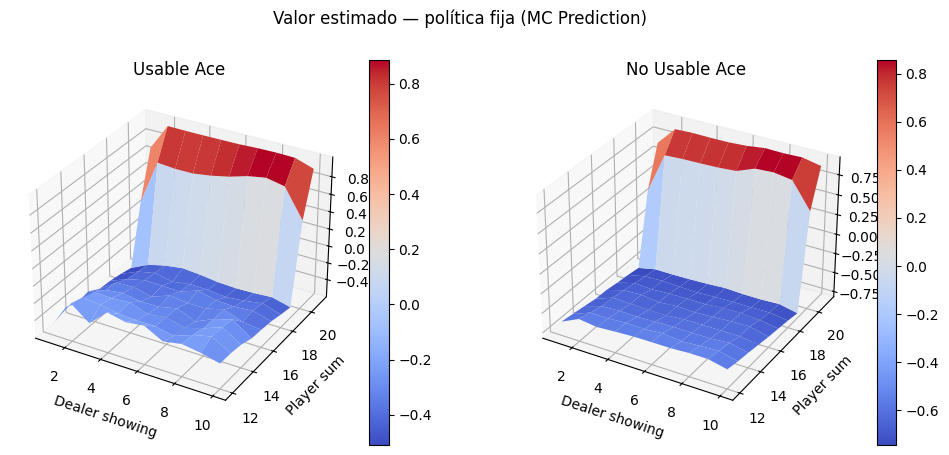

In [8]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def plot_value_function(V, title="Valor de la política"):
    # Separar estados con y sin As usable
    player_sums = np.arange(12, 22)
    dealer_cards = np.arange(1, 11)
    X, Y = np.meshgrid(dealer_cards, player_sums)

    def get_Z(usable_ace):
        Z = np.zeros(X.shape)
        for i, ps in enumerate(player_sums):
            for j, dc in enumerate(dealer_cards):
                Z[i, j] = V.get((ps, dc, usable_ace), 0)
        return Z

    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(121, projection='3d')
    surf = ax.plot_surface(X, Y, get_Z(True), cmap="coolwarm")
    ax.set_title("Usable Ace")
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    fig.colorbar(surf, ax=ax)

    ax = fig.add_subplot(122, projection='3d')
    surf = ax.plot_surface(X, Y, get_Z(False), cmap="coolwarm")
    ax.set_title("No Usable Ace")
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    fig.colorbar(surf, ax=ax)

    plt.suptitle(title)
    plt.show()

plot_value_function(V, "Valor estimado — política fija (MC Prediction)")


#### Ejemplo encontrando la política óptima (on-policy)

La **evaluación de política** en Monte Carlo se realiza ejecutando muchos episodios para una política fija y se calcula una **función de valor-acción** aproximada $q_\pi(s, a)$, que con suficientes episodios converge al valor verdadero, como se vio en el ejemplo anterior.



Recordemos que $q_\pi$ es el valor esperado de la recompensa acumulada si tomamos acción $a$ en estado $s$ y luego seguimos la política $\pi$:

$$
q_\pi(s,a) = \mathbb{E}_\pi \Big[ G_t \mid S_t=s, A_t=a \Big]
$$

Luego viene la mejora de política, que se hace volviendo la política greedy respecto al valor actual $q$.
No se necesita un modelo del entorno, ya que la política puede definirse directamente a partir de $q(s, a)$:

$$
\pi(s) = \arg\max_a q(s, a)
$$

Cada nueva política $\pi_{k+1}$ se construye haciendo que sea greedy respecto a $q_{\pi_k}$.

Según el teorema de mejora de política, para todo estado $s$:

$$
q_{\pi_k}(s, \pi_{k+1}(s))  \geq v_{\pi_k}(s)
$$

(Sutton & Barto, p98)

Esto garantiza que $\pi_{k+1}$ es **igual o mejor** que $\pi_k$; si no hay mejora, ambas son **óptimas**.
Así, el proceso converge hacia la **política óptima** $\pi_*$ y la **función de valor óptima** $q_*$, sin conocer la dinámica del entorno, solo mediante episodios de muestra.

Sin embargo, para que esto funcione se hacen dos suposiciones que restringen el campo de aplicación de la solución:

1. Todas las acciones se prueban en todos los estados.
2. Que la **evaluación de política** se hace con un **número infinito de episodios**.

La segunda suposición se puede eliminar. En lugar de esperar a que la evaluación converja completamente antes de mejorar la política, se puede **alternar evaluación e iteración parcialmente** —similar a **value iteration**—, donde la política se mejora después de cada episodio:

1. Se usa el episodio para actualizar $q_\pi(s, a)$.
2. Luego, se mejora la política en los estados visitados.

Este procedimiento se conoce como **Monte Carlo ES** (*Exploring Starts*), y constituye una forma práctica y convergente de **iteración de política con Monte Carlo**.

Usemos este metodo para encontrar la política óptima en el Black Jack:

In [9]:
import gymnasium as gym
import numpy as np
from collections import defaultdict
import matplotlib.pyplot as plt

# Entorno Blackjack
env = gym.make("Blackjack-v1", sab=True)

# Hiperparámetros
EPISODES = 500_000
GAMMA = 1.0
EPSILON = 0.1  # ε-greedy

# Inicializar Q(s,a) y contadores
Q = defaultdict(lambda: np.zeros(env.action_space.n))
returns_sum = defaultdict(lambda: np.zeros(env.action_space.n))
returns_count = defaultdict(lambda: np.zeros(env.action_space.n))

def epsilon_greedy(Q_s, epsilon=0.1):
    """Selecciona acción usando ε-greedy sobre Q_s"""
    if np.random.rand() < epsilon:
        return np.random.choice(len(Q_s))
    else:
        return np.argmax(Q_s)

for episode_num in range(EPISODES):
    # Generar episodio
    episode = []
    state, _ = env.reset()
    done = False
    while not done:
        action = epsilon_greedy(Q[state], EPSILON)
        next_state, reward, done, truncated, _ = env.step(action)
        episode.append((state, action, reward))
        state = next_state

    # Calcular retornos y actualizar Q
    G = 0
    visited = set()
    for state, action, reward in reversed(episode):
        G = GAMMA * G + reward
        returns_sum[state][action] += G
        returns_count[state][action] += 1
        Q[state][action] = returns_sum[state][action] / returns_count[state][action]
        visited.add((state, action))

# Derivar política final (ε=0 greedy)
policy = defaultdict(int)
for state, actions in Q.items():
    policy[state] = np.argmax(actions)

print("Entrenamiento completado. Ejemplo de política aprendida:")
for s in list(policy.keys())[:10]:
    print(f"Estado {s} -> Acción {policy[s]}")


Entrenamiento completado. Ejemplo de política aprendida:
Estado (18, 2, 0) -> Acción 0
Estado (13, 4, 0) -> Acción 0
Estado (16, 2, 0) -> Acción 0
Estado (16, 10, 0) -> Acción 0
Estado (6, 10, 0) -> Acción 1
Estado (15, 8, 0) -> Acción 1
Estado (21, 1, 1) -> Acción 0
Estado (17, 6, 0) -> Acción 0
Estado (12, 6, 0) -> Acción 0
Estado (20, 1, 0) -> Acción 0


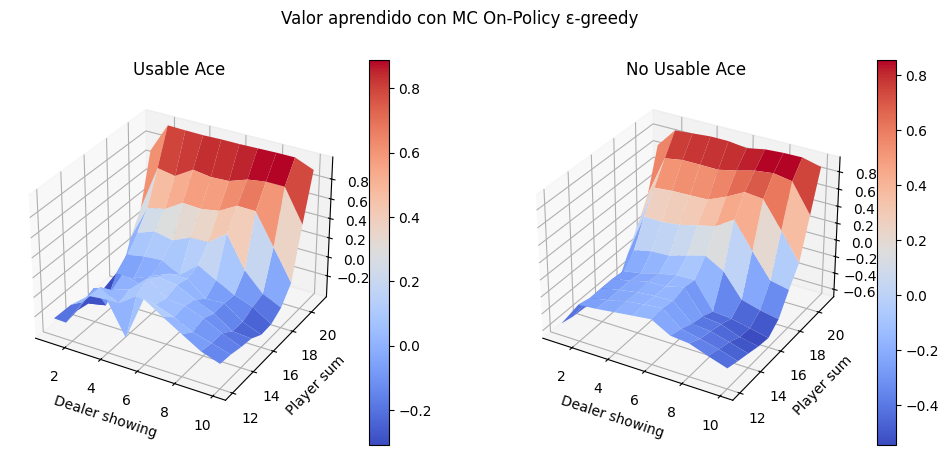

In [10]:
# Calcular V(s) = max_a Q(s,a)
V = defaultdict(float)
for state, actions in Q.items():
    V[state] = np.max(actions)

# Función para graficar
from mpl_toolkits.mplot3d import Axes3D

def plot_value_function(V, title="Valor estimado"):
    player_sums = np.arange(12,22)
    dealer_cards = np.arange(1,11)
    X, Y = np.meshgrid(dealer_cards, player_sums)

    def get_Z(usable_ace):
        Z = np.zeros(X.shape)
        for i, ps in enumerate(player_sums):
            for j, dc in enumerate(dealer_cards):
                Z[i,j] = V.get((ps, dc, usable_ace), 0)
        return Z

    fig = plt.figure(figsize=(12,5))
    ax = fig.add_subplot(121, projection='3d')
    surf = ax.plot_surface(X, Y, get_Z(True), cmap="coolwarm")
    ax.set_title("Usable Ace")
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    fig.colorbar(surf, ax=ax)

    ax = fig.add_subplot(122, projection='3d')
    surf = ax.plot_surface(X, Y, get_Z(False), cmap="coolwarm")
    ax.set_title("No Usable Ace")
    ax.set_xlabel("Dealer showing")
    ax.set_ylabel("Player sum")
    fig.colorbar(surf, ax=ax)

    plt.suptitle(title)
    plt.show()

plot_value_function(V, "Valor aprendido con MC On-Policy ε-greedy")


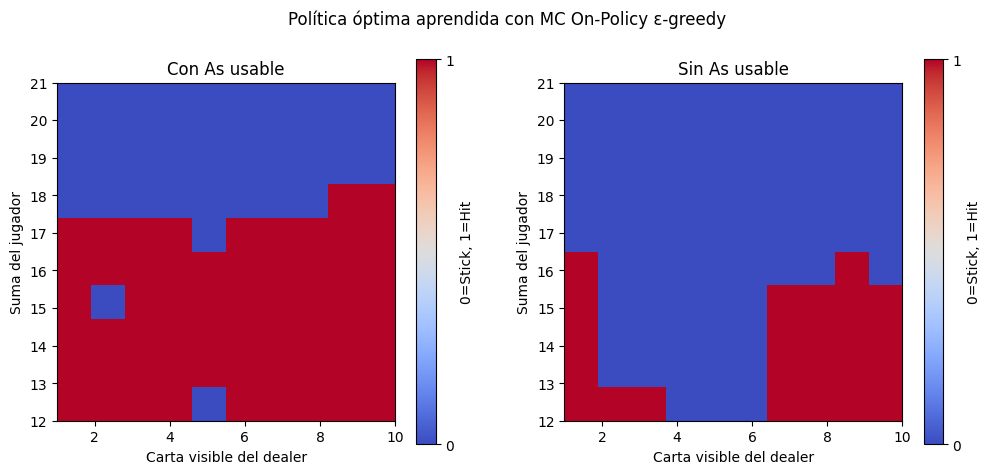

In [11]:
import matplotlib.pyplot as plt
import numpy as np

def plot_policy(policy, title="Política óptima"):
    player_sums = np.arange(12, 22)       # Suma del jugador
    dealer_cards = np.arange(1, 11)       # Carta visible del dealer
    X, Y = np.meshgrid(dealer_cards, player_sums)

    # Matriz para el mapa de colores
    Z_usable = np.zeros(X.shape)
    Z_no_usable = np.zeros(X.shape)

    for i, ps in enumerate(player_sums):
        for j, dc in enumerate(dealer_cards):
            Z_usable[i, j] = policy.get((ps, dc, True), 0)   # Acción con As usable
            Z_no_usable[i, j] = policy.get((ps, dc, False), 0)  # Acción sin As usable

    fig, axes = plt.subplots(1, 2, figsize=(12,5))

    im1 = axes[0].imshow(Z_usable, cmap="coolwarm", origin="lower", extent=[1,10,12,21])
    axes[0].set_title("Con As usable")
    axes[0].set_xlabel("Carta visible del dealer")
    axes[0].set_ylabel("Suma del jugador")
    fig.colorbar(im1, ax=axes[0], ticks=[0,1], label="0=Stick, 1=Hit")

    im2 = axes[1].imshow(Z_no_usable, cmap="coolwarm", origin="lower", extent=[1,10,12,21])
    axes[1].set_title("Sin As usable")
    axes[1].set_xlabel("Carta visible del dealer")
    axes[1].set_ylabel("Suma del jugador")
    fig.colorbar(im2, ax=axes[1], ticks=[0,1], label="0=Stick, 1=Hit")

    plt.suptitle(title)
    plt.show()

# Llamada a la función
plot_policy(policy, "Política óptima aprendida con MC On-Policy ε-greedy")


## Metodos diferencias temporales:
Con el metódo de Monte Carlo se tenía que esperar al fin del episodio para para calcular el valor esperado $v_\pi(s_t)$. Los métodos de diferencias temporales buscan optimizar el proceso actualizando la función de valor en cada paso.

La función de valor en los metodos de diferncias temporales se actualiza de la siguiente forma:

$$
V(S_t) \leftarrow V(S_t) + \alpha \left[ R_{t+1} + \gamma V(S_{t+1}) - V(S_t) \right]
$$

Donde:

$V(S_t)$: Valor estimado del estado actual

$\alpha$: Controla qué tan rápido aprendemos (valores pequeños = aprendizaje lento pero estable)

$R_{t+1}$: Recompensa inmediata recibida

$\gamma$: Cuánto valoramos recompensas futuras vs. inmediatas

$V(S_{t+1})$: Nuestra estimación del valor del próximo estado

$[R_{t+1} + \gamma V(S_{t+1}) - V(S_t)]$: Error de diferencia temporal. Es la diferencia entre lo que esperábamos y lo que realmente obtuvimos más lo que esperamos obtener después

Los métodos de Diferencias Temporales (TD) presentan dos ventajas clave:

* Frente a la Programación Dinámica (DP): No necesitan un modelo previo del entorno (cómo responde a las acciones).

* Frente a Monte Carlo: Son incremental y se pueden ejecutar online. Aprenden en cada paso, sin tener que esperar a que termine un episodio completo para obtener una recompensa. Esto es crucial en entornos con episodios muy largos, tareas continuas (sin episodios) o cuando se realizan acciones exploratorias, ya que acelera significativamente el aprendizaje.


### **Q-learning**:

Uno de los primeros avances en el aprendizaje por refuerzo fue el desarrollo de un algoritmo de control TD fuera de la política conocido como Q-learning (Watkins, 1989), definido por

$$
Q(S_t, A_t) \leftarrow Q(S_t, A_t) + \alpha \left[ R_{t+1} + \gamma \max_a Q(S_{t+1}, a) - Q(S_t, A_t) \right]
$$

donde:

- $ Q(s_t, a_t)$: valor estimado de tomar la acción $ a_t$ en el estado $ s_t$  
- $ \alpha$: tasa de aprendizaje (learning rate)  
- $ r_{t+1}$: recompensa recibida tras ejecutar la acción  
- $ \gamma$: factor de descuento (discount factor)  
- $ \max_{a'} Q(s_{t+1}, a')$: valor estimado máximo del siguiente estado  
- El término entre corchetes $[\,]$ es el **error de temporal-diferencia (TD error)**.


El algoritmo Q-learning es de aprendizaje por refuerzo fuera de política (off-policy). En cada paso, el agente observa el resultado de una acción, recibe una recompensa y llega a un nuevo estado, así actualiza su estimación del valor de esa acción combinando la recompensa inmediata con el valor máximo esperado de las acciones futuras. Con el tiempo, al explorar y actualizar según la fórmula de Q-learning, el agente converge hacia una política óptima que maximiza la recompensa acumulada esperada.

### Ejemplo: Encontrar la ruta optima



In [18]:
# Ejemplo básico
import numpy as np
import random

# Parámetros
n_rows, n_cols = 5, 5
goal = (n_rows-1, n_cols-1)  # objetivo en la esquina inferior derecha
alpha = 0.1    # Factor de actualización
gamma = 0.9    # Factor de descuento
epsilon = 0.2  # epsilon greedy
episodes = 50

# Inicializamos tabla Q con ceros
Q = np.zeros((n_rows, n_cols, 4))  # 4 acciones

# Lista para guardar la recompenza por episodio
rewards_per_episode = []

# Función para elegir acción (ε-greedy)
def choose_action(state):
    if random.uniform(0,1) < epsilon:
        return random.randint(0,3)  # explorar
    else:
        return np.argmax(Q[state[0], state[1]])

# Función para ejecutar acción
def step(state, action):
    r, c = state
    if action == 0 and r > 0:        # arriba
        r -= 1
    elif action == 1 and r < n_rows-1:  # abajo
        r += 1
    elif action == 2 and c > 0:      # izquierda
        c -= 1
    elif action == 3 and c < n_cols-1:  # derecha
        c += 1

    new_state = (r, c)
    reward = 10 if new_state == goal else -1 # 10 si llego al objetivo, -1 por cada paso
    done = new_state == goal
    return new_state, reward, done

# Entrenamiento
for ep in range(episodes):
    state = (0,0)
    done = False
    total_reward = 0
    i = 0
    while not done:
        i += 1
        action = choose_action(state)
        next_state, reward, done = step(state, action)
        # Actualizar Q
        Q[state[0], state[1], action] += alpha * (
            reward + gamma * np.max(Q[next_state[0], next_state[1]]) - Q[state[0], state[1], action]
        )
        state = next_state
        total_reward += reward
    rewards_per_episode.append(total_reward)
    print(f"ep {ep}. Pasos {i}")

# Política aprendidan_rows
policy = np.chararray((n_rows, n_cols), unicode=True)
actions = ['↑','↓','←','→']

# Grafico la politica aprendida
for i in range(n_rows):
    for j in range(n_cols):
        if (i,j) == goal:
            policy[i,j] = 'G'
        else:
            policy[i,j] = actions[np.argmax(Q[i,j])]


print("Política aprendida:")
print(policy)


ep 0. Pasos 149
ep 1. Pasos 29
ep 2. Pasos 27
ep 3. Pasos 17
ep 4. Pasos 21
ep 5. Pasos 38
ep 6. Pasos 31
ep 7. Pasos 19
ep 8. Pasos 21
ep 9. Pasos 19
ep 10. Pasos 27
ep 11. Pasos 44
ep 12. Pasos 48
ep 13. Pasos 24
ep 14. Pasos 39
ep 15. Pasos 20
ep 16. Pasos 24
ep 17. Pasos 18
ep 18. Pasos 24
ep 19. Pasos 13
ep 20. Pasos 10
ep 21. Pasos 41
ep 22. Pasos 11
ep 23. Pasos 23
ep 24. Pasos 31
ep 25. Pasos 15
ep 26. Pasos 18
ep 27. Pasos 10
ep 28. Pasos 24
ep 29. Pasos 11
ep 30. Pasos 9
ep 31. Pasos 10
ep 32. Pasos 18
ep 33. Pasos 16
ep 34. Pasos 9
ep 35. Pasos 19
ep 36. Pasos 9
ep 37. Pasos 18
ep 38. Pasos 14
ep 39. Pasos 22
ep 40. Pasos 14
ep 41. Pasos 20
ep 42. Pasos 10
ep 43. Pasos 11
ep 44. Pasos 8
ep 45. Pasos 12
ep 46. Pasos 11
ep 47. Pasos 19
ep 48. Pasos 10
ep 49. Pasos 10
Política aprendida:
[['↓' '→' '←' '↑' '↓']
 ['→' '←' '↓' '↓' '↓']
 ['←' '→' '↓' '↓' '↓']
 ['↓' '→' '→' '→' '↓']
 ['→' '→' '→' '→' 'G']]


Graficamos como fue evoluciando la recompenza en cada iteración:

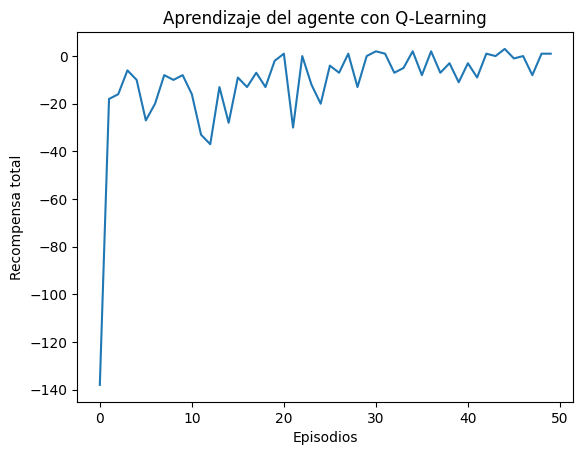

In [19]:
import matplotlib.pyplot as plt

plt.plot(rewards_per_episode)
plt.xlabel("Episodios")
plt.ylabel("Recompensa total")
plt.title("Aprendizaje del agente con Q-Learning")
plt.show()


#### Q-Learning en CliffWalking

El entorno que vamos a usar para este ejemplo es CliffWalking-v1, que representa un escenario simple pero muy ilustrativo:

- El agente comienza en la esquina inferior izquierda de un tablero.
- La meta se encuentra en la esquina inferior derecha.
- Entre el inicio y la meta hay un "acantilado" que termina el episodio si el agente cae en él, con una penalización fuerte.
- Cada paso que el agente da tiene un costo pequeño, por lo que queremos que aprenda a llegar a la meta rápidamente y evitando el acantilado.

**Objetivo del ejemplo**

Aprender una **política óptima** que permita al agente:

1. Alcanzar la meta con la mayor recompensa posible.
2. Evitar caer en el acantilado.
3. Balancear exploración(probar nuevas acciones) y explotación (usar lo que ya sabe) usando la estrategia ε-greedy.

**Para esto haremos los siguientes pasos:**

- Inicializaremos una Q-Table para representar el conocimiento del agente.
- Implementaremos una política ε-greedy para seleccionar acciones.
- Aplicaremos  regla de actualización de Q-Learning basada en el error temporal-diferencial (TD error):

$$
Q(s, a) \gets Q(s, a) + \alpha \Big[ r + \gamma \max_{a'} Q(s', a') - Q(s, a) \Big]
$$

Al final, evaluaremos cómo se comporta el agente entrenado y verificaremos si ha aprendido a evitar el acantilado mientras alcanza la meta.


In [25]:
# Q-Learning en CliffWalking-v0
# ---------------------------------
# Objetivo: Aprender una política óptima para llegar a la meta evitando el acantilado
# usando el algoritmo de aprendizaje por refuerzo Q-Learning.

import gymnasium as gym
import numpy as np
from collections import defaultdict

from gymnasium.wrappers import RecordEpisodeStatistics, RecordVideo

# Hiperparámetros
ALPHA = 0.1        # Tasa de aprendizaje (qué tanto se actualiza la Q-table)
GAMMA = 0.99       # Factor de descuento (importancia de recompensas futuras)
EPSILON = 0.1      # Probabilidad de exploración (ε-greedy)
EPISODES = 1500     # Cantidad de episodios de entrenamiento

# Crear entorno
env = gym.make("CliffWalking-v1", render_mode="rgb_array")

env = RecordVideo(env,
                  video_folder="cliff-training",
                  episode_trigger=lambda x: x % 100 == 0)

# Q-Table representada como diccionario: Q[state][action]
Q = defaultdict(lambda: np.zeros(env.action_space.n), render_mode="rgb_array")

def epsilon_greedy_policy(state):
    """Selecciona una acción según la política ε-greedy."""
    if np.random.random() < EPSILON:
        return env.action_space.sample()  # acción aleatoria (exploración)
    else:
        return np.argmax(Q[state])        # acción con mayor valor Q (explotación)

# Entrenamiento
for episode in range(EPISODES):
    state, _ = env.reset()
    done = False

    while not done:
        # 1️⃣ Elegir acción según política ε-greedy
        action = epsilon_greedy_policy(state)

        # 2️⃣ Ejecutar la acción en el entorno
        next_state, reward, terminated, truncated, _ = env.step(action)

        # 3️⃣ Calcular el valor objetivo (TD target)
        #    Q-Learning es off-policy: usa la mejor acción futura conocida (greedy)
        best_next_action = np.argmax(Q[next_state])
        td_target = reward + GAMMA * Q[next_state][best_next_action]

        # 4️⃣ Calcular el error temporal (TD error)
        td_error = td_target - Q[state][action]

        # 5️⃣ Actualizar la Q-Table
        Q[state][action] += ALPHA * td_error

        # 6️⃣ Moverse al siguiente estado
        state = next_state
        done = terminated or truncated

# ------------------------------------------------------------
# EVALUACIÓN DEL AGENTE ENTRENADO
# ------------------------------------------------------------
state, _ = env.reset()
env.render()

done = False
total_reward = 0

print("\n--- EJECUCIÓN DEL AGENTE ENTRENADO ---")
while not done:
    action = np.argmax(Q[state])  # acción con mayor Q conocida
    next_state, reward, terminated, truncated, _ = env.step(action)
    total_reward += reward
    env.render()  # muestra el entorno paso a paso en consola
    state = next_state
    done = terminated or truncated

print(f"\nRecompensa total del episodio: {total_reward}")
env.close()


/home/tomas/.local/lib/python3.10/site-packages/gymnasium/wrappers/rendering.py:434: UserWarning: WARN: Unable to save last video! Did you call close()?
  logger.warn("Unable to save last video! Did you call close()?")


✅ Entrenamiento finalizado

--- EJECUCIÓN DEL AGENTE ENTRENADO ---

Recompensa total del episodio: -13
